# Designing Low-Carbon Concrete with a Surrogate of Laboratory Experiments

Run it top to bottom. Every figure is produced here and saved in `images/`.

**Data (real):** the Concrete Compressive Strength dataset of I-Cheng Yeh (1998), 1,030 laboratory
compression tests on 425 concrete mixes, from the UCI Machine Learning Repository (CC BY 4.0).

## Setup

In [1]:
# Python ≥3.8 is required
import sys
assert sys.version_info >= (3, 8)

# Scikit-Learn ≥1.0 is required
import sklearn
assert sklearn.__version__ >= "1.0"

# Common imports
import os
import time
import numpy as np
import pandas as pd

# To make this notebook's output stable across runs
np.random.seed(42)

# To plot pretty figures
import matplotlib as mpl
import matplotlib.pyplot as plt
mpl.rc('axes', labelsize=13)
mpl.rc('xtick', labelsize=11)
mpl.rc('ytick', labelsize=11)

# Where to save the figures and the data
PROJECT_ROOT_DIR = "."
IMAGES_PATH = os.path.join(PROJECT_ROOT_DIR, "images")
DATA_PATH = os.path.join(PROJECT_ROOT_DIR, "datasets", "concrete")
os.makedirs(IMAGES_PATH, exist_ok=True)
os.makedirs(DATA_PATH, exist_ok=True)

def save_fig(fig_id, tight_layout=True, fig_extension="png", resolution=150):
    path = os.path.join(IMAGES_PATH, fig_id + "." + fig_extension)
    print("Saving figure", fig_id)
    if tight_layout:
        plt.tight_layout()
    plt.savefig(path, format=fig_extension, dpi=resolution)

In [2]:
import warnings
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)
warnings.filterwarnings("ignore", message="All-NaN slice")

## Get the Data

In [3]:
import urllib.request
import zipfile

DATA_URL = "https://archive.ics.uci.edu/static/public/165/concrete+compressive+strength.zip"
COLUMNS = ["cement", "slag", "fly_ash", "water", "superplasticizer", "coarse_agg", "fine_agg", "age", "strength"]

def fetch_concrete_data(url=DATA_URL, path=DATA_PATH):
    csv_path = os.path.join(path, "concrete_data.csv")
    if not os.path.exists(csv_path):
        zip_path = os.path.join(path, "concrete.zip")
        urllib.request.urlretrieve(url, zip_path)
        with zipfile.ZipFile(zip_path) as z:
            z.extract("Concrete_Data.xls", path)
        df = pd.read_excel(os.path.join(path, "Concrete_Data.xls"))
        df.columns = COLUMNS
        df.to_csv(csv_path, index=False)
    return pd.read_csv(csv_path)

concrete = fetch_concrete_data()
concrete.head()

,cement,slag,fly_ash,water,superplasticizer,coarse_agg,fine_agg,age,strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075


In [4]:
concrete.info()

<class 'pandas.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   cement            1030 non-null   float64
 1   slag              1030 non-null   float64
 2   fly_ash           1030 non-null   float64
 3   water             1030 non-null   float64
 4   superplasticizer  1030 non-null   float64
 5   coarse_agg        1030 non-null   float64
 6   fine_agg          1030 non-null   float64
 7   age               1030 non-null   int64  
 8   strength          1030 non-null   float64
dtypes: float64(8), int64(1)
memory usage: 72.6 KB


In [5]:
concrete.describe().round(1)

,cement,slag,fly_ash,water,superplasticizer,coarse_agg,fine_agg,age,strength
count,1030.0,1030.0,1030.0,1030.0,1030.0,1030.0,1030.0,1030.0,1030.0
mean,281.2,73.9,54.2,181.6,6.2,972.9,773.6,45.7,35.8
std,104.5,86.3,64.0,21.4,6.0,77.8,80.2,63.2,16.7
min,102.0,0.0,0.0,121.8,0.0,801.0,594.0,1.0,2.3
25%,192.4,0.0,0.0,164.9,0.0,932.0,731.0,7.0,23.7
50%,272.9,22.0,0.0,185.0,6.4,968.0,779.5,28.0,34.4
75%,350.0,143.0,118.3,192.0,10.2,1029.4,824.0,56.0,46.1
max,540.0,359.4,200.1,247.0,32.2,1145.0,992.6,365.0,82.6


Saving figure attribute_histogram_plots


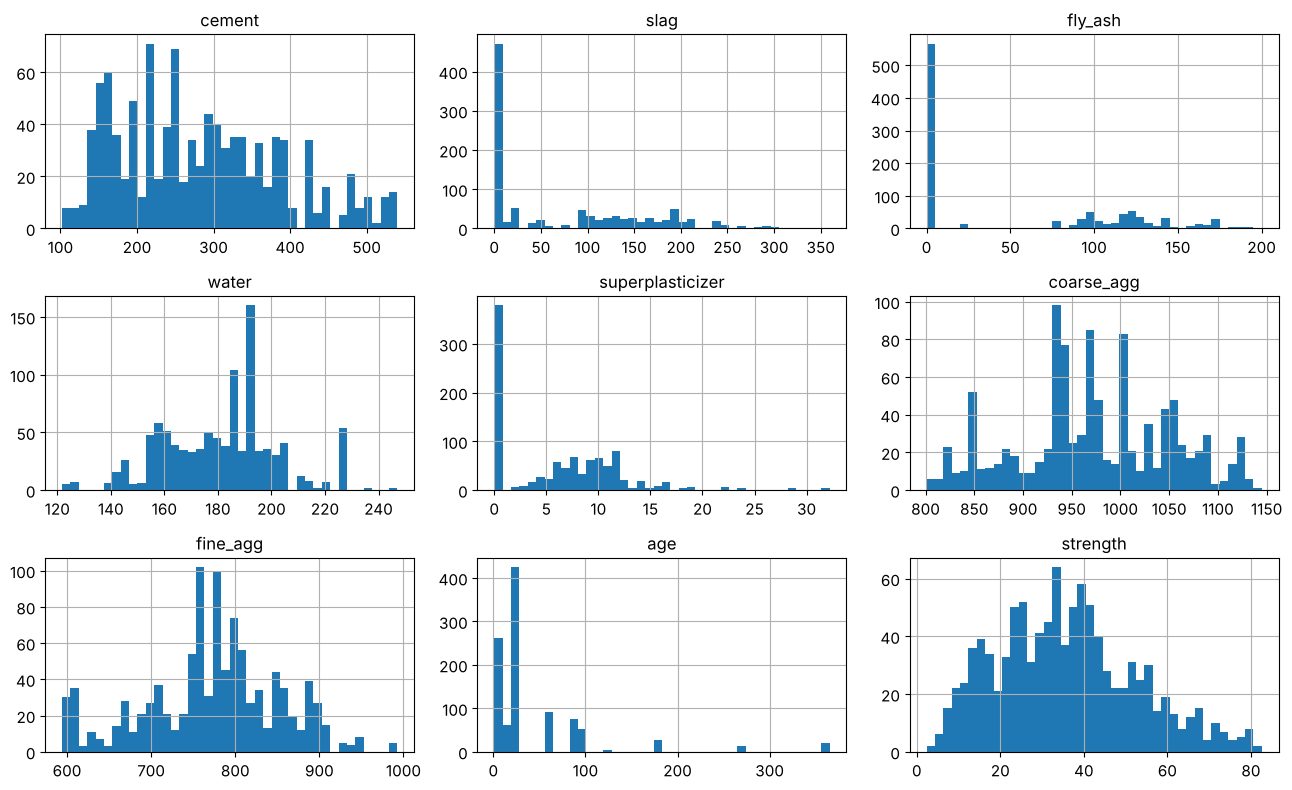

In [6]:
concrete.hist(bins=40, figsize=(13, 8))
save_fig("attribute_histogram_plots")
plt.show()

In [7]:
concrete["age"].value_counts().sort_index()

age
1        2
3      134
7      126
14      62
28     425
56      91
90      54
91      22
100     52
120      3
180     26
270     13
360      6
365     14
Name: count, dtype: int64

In [8]:
print("Exact duplicate rows:", concrete.duplicated().sum())
concrete = concrete.drop_duplicates().reset_index(drop=True)
INGREDIENTS = COLUMNS[:7]
concrete["mix_id"] = concrete.groupby(INGREDIENTS).ngroup()
print(f"{len(concrete)} tests on {concrete.mix_id.nunique()} different mixes")
concrete.groupby("mix_id").size().value_counts().sort_index().rename("number of mixes")

Exact duplicate rows: 25
1005 tests on 428 different mixes


1    246
2     42
3      7
4     38
5     77
6     12
7      3
8      3
Name: number of mixes, dtype: int64

In [9]:
DENSITY = pd.Series({"cement": 3150, "slag": 2900, "fly_ash": 2300, "water": 1000,
                     "superplasticizer": 1200, "coarse_agg": 2700, "fine_agg": 2650})  # kg/m³
volume = (concrete[INGREDIENTS] / DENSITY).sum(axis=1)
print(f"Absolute volume of the ingredients per m³ of concrete: {volume.mean():.3f} ± {volume.std():.3f} m³")
print(f"(the rest, about {100 * (1 - volume.mean()):.1f}%, is entrapped air)")

Absolute volume of the ingredients per m³ of concrete: 0.977 ± 0.015 m³
(the rest, about 2.3%, is entrapped air)


## Create a Test Set

In [10]:
from sklearn.model_selection import GroupShuffleSplit

splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(splitter.split(concrete, groups=concrete.mix_id))
train_set, test_set = concrete.iloc[train_idx].copy(), concrete.iloc[test_idx].copy()
print(len(train_set), "training tests,", len(test_set), "test tests")
print("Mixes in both sets:", len(set(train_set.mix_id) & set(test_set.mix_id)))

810 training tests, 195 test tests
Mixes in both sets: 0


## Discover and Visualize the Data

Saving figure strength_vs_age_plot


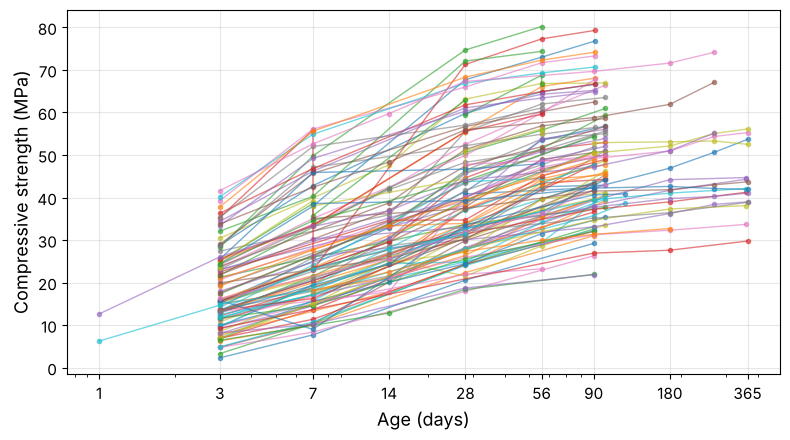

107 mixes tested at 4 or more ages


In [11]:
fig, ax = plt.subplots(figsize=(8, 4.5))
multi = train_set.groupby("mix_id").filter(lambda g: g.age.nunique() >= 4)
for i, (mid, g) in enumerate(multi.groupby("mix_id")):
    g = g.sort_values("age")
    ax.plot(g.age, g.strength, "o-", ms=3, lw=1, alpha=0.6)
ax.set_xscale("log")
ax.set_xlabel("Age (days)")
ax.set_ylabel("Compressive strength (MPa)")
ax.set_xticks([1, 3, 7, 14, 28, 56, 90, 180, 365])
ax.xaxis.set_major_formatter(mpl.ticker.ScalarFormatter())
ax.grid(True, alpha=0.3)
save_fig("strength_vs_age_plot")
plt.show()
print(f"{multi.mix_id.nunique()} mixes tested at 4 or more ages")

Saving figure abrams_law_plot


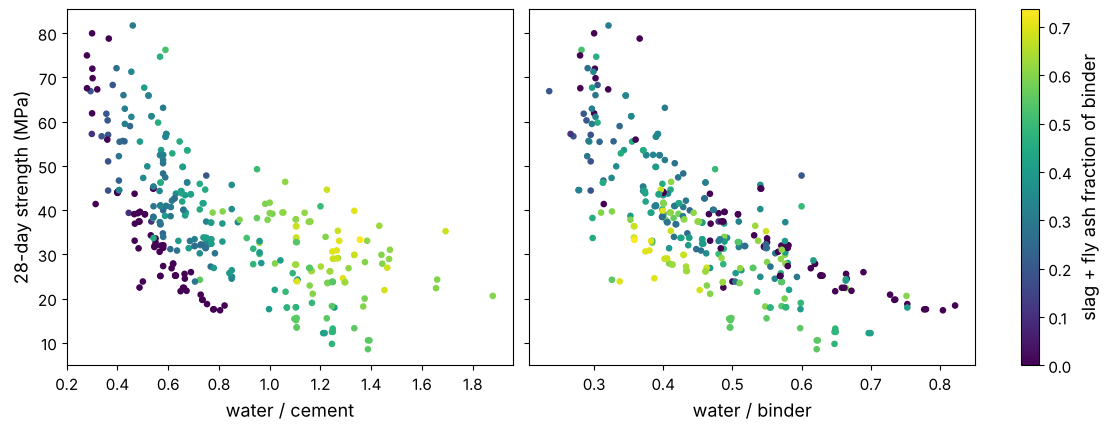

In [12]:
d28 = train_set[train_set.age == 28]
binder = d28.cement + d28.slag + d28.fly_ash
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True, layout="constrained")
for ax, ratio, label in ((axes[0], d28.water / d28.cement, "water / cement"),
                         (axes[1], d28.water / binder, "water / binder")):
    sc = ax.scatter(ratio, d28.strength, c=(d28.slag + d28.fly_ash) / binder, cmap="viridis", s=14)
    ax.set_xlabel(label)
axes[0].set_ylabel("28-day strength (MPa)")
fig.colorbar(sc, ax=axes, label="slag + fly ash fraction of binder")
save_fig("abrams_law_plot", tight_layout=False)
plt.show()

In [13]:
features_df = train_set.copy()
b = features_df.cement + features_df.slag + features_df.fly_ash
features_df["water_binder"] = features_df.water / b
features_df["log_age"] = np.log(features_df.age)
features_df.drop(columns="mix_id").corr()["strength"].sort_values(ascending=False).round(3)

strength            1.000
log_age             0.582
cement              0.458
age                 0.354
superplasticizer    0.342
slag                0.099
fly_ash            -0.049
coarse_agg         -0.113
fine_agg           -0.203
water              -0.258
water_binder       -0.593
Name: strength, dtype: float64

## Prepare the Data

In [14]:
from sklearn.base import BaseEstimator, TransformerMixin

FEATURES = INGREDIENTS + ["log_age", "water_binder", "slag_binder", "ash_binder", "sp_binder", "agg_binder"]

class MixFeatures(BaseEstimator, TransformerMixin):
    """Adds the ratios that concrete technologists use: water/binder (Abrams' law),
    the share of slag and fly ash in the binder, superplasticizer and aggregate per binder,
    and log(age), since strength grows roughly with the logarithm of time."""
    def fit(self, X, y=None):
        return self
    def __sklearn_is_fitted__(self):
        return True
    def transform(self, X):
        X = np.asarray(X, dtype=float)
        c, s, f, w, sp, ca, fa, age = X.T
        b = c + s + f
        return np.c_[X[:, :7], np.log(age), w / b, s / b, f / b, sp / b, (ca + fa) / b]

X_train = train_set[COLUMNS[:8]].values
y_train = train_set.strength.values
groups = train_set.mix_id.values
X_test = test_set[COLUMNS[:8]].values
y_test = test_set.strength.values
pd.DataFrame(MixFeatures().transform(X_train[:3]), columns=FEATURES).round(3)

,cement,slag,fly_ash,water,superplasticizer,coarse_agg,fine_agg,log_age,water_binder,slag_binder,ash_binder,sp_binder,agg_binder
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,3.332,0.30,0.0,0.0,0.005,3.178
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,3.332,0.30,0.0,0.0,0.005,3.206
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,5.598,0.48,0.3,0.0,0.000,3.213


## Select and Train a Model

In [15]:
from sklearn.base import RegressorMixin
from scipy.optimize import curve_fit

class AbramsModel(BaseEstimator, RegressorMixin):
    """A physics baseline: Abrams' law on the water/binder ratio, times the ACI 209 strength-gain
    curve, with slag and fly ash slowing down the gain and changing the final strength."""
    @staticmethod
    def _f(Z, A, k, tau0, tau_s, tau_f, a_s, a_f):
        wb, slag, ash, age = Z
        tau = np.abs(tau0) + np.abs(tau_s) * slag + np.abs(tau_f) * ash
        return A * np.exp(-k * wb) * (1 + a_s * slag + a_f * ash) * age / (tau + age)
    def _z(self, X):
        F = MixFeatures().transform(X)
        return F[:, 8], F[:, 9], F[:, 10], np.exp(F[:, 7])
    def fit(self, X, y):
        self.params_, _ = curve_fit(self._f, self._z(X), y, p0=[150, 2, 3, 5, 10, 0, 0], maxfev=50000)
        return self
    def predict(self, X):
        return self._f(self._z(X), *self.params_)

abrams = AbramsModel().fit(X_train, y_train)
print("A, k, tau0, tau_slag, tau_ash, a_slag, a_ash =", abrams.params_.round(2))
rmse = lambda y, p: np.sqrt(np.mean((y - p) ** 2))
print(f"Training RMSE: {rmse(y_train, abrams.predict(X_train)):.2f} MPa")

A, k, tau0, tau_slag, tau_ash, a_slag, a_ash = [ 1.615e+02  2.440e+00  4.940e+00  7.220e+00  7.190e+00 -1.400e-01
 -3.900e-01]
Training RMSE: 7.47 MPa


In [16]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.neural_network import MLPRegressor

models = {
    "Linear regression": make_pipeline(MixFeatures(), StandardScaler(), LinearRegression()),
    "Abrams' law + age (physics)": AbramsModel(),
    "Random forest": make_pipeline(MixFeatures(), RandomForestRegressor(n_estimators=300, random_state=42)),
    "Gradient boosting": make_pipeline(MixFeatures(), HistGradientBoostingRegressor(max_iter=500, random_state=42)),
    "Neural network (MLP)": make_pipeline(MixFeatures(), StandardScaler(),
                                          MLPRegressor(hidden_layer_sizes=(64, 64), alpha=1e-3, max_iter=3000,
                                                       early_stopping=True, random_state=42)),
}
gbr = models["Gradient boosting"].fit(X_train, y_train)
print(f"Gradient boosting, training RMSE: {rmse(y_train, gbr.predict(X_train)):.2f} MPa")

Gradient boosting, training RMSE: 1.18 MPa


In [17]:
from sklearn.model_selection import KFold, GroupKFold, cross_val_predict

p_random = cross_val_predict(models["Gradient boosting"], X_train, y_train, cv=KFold(5, shuffle=True, random_state=42))
p_group = cross_val_predict(models["Gradient boosting"], X_train, y_train, cv=GroupKFold(5), groups=groups)
print(f"5-fold CV, random folds:        RMSE {rmse(y_train, p_random):.2f} MPa")
print(f"5-fold CV, grouped by mix:      RMSE {rmse(y_train, p_group):.2f} MPa")

5-fold CV, random folds:        RMSE 4.52 MPa
5-fold CV, grouped by mix:      RMSE 5.87 MPa


In [18]:
cv = GroupKFold(n_splits=5)
cv_scores, oof = {}, {}
for name, model in models.items():
    oof[name] = cross_val_predict(model, X_train, y_train, cv=cv, groups=groups)
    cv_scores[name] = rmse(y_train, oof[name])
pd.Series(cv_scores, name="grouped 5-fold CV RMSE (MPa)").round(2).sort_values()

Gradient boosting              5.87
Random forest                  5.90
Neural network (MLP)           6.49
Linear regression              7.52
Abrams' law + age (physics)    7.74
Name: grouped 5-fold CV RMSE (MPa), dtype: float64

In [19]:
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern, ConstantKernel as C, WhiteKernel

gp_model = make_pipeline(MixFeatures(), StandardScaler(), GaussianProcessRegressor(
    C(1.0) * Matern(np.ones(13), (1e-2, 1e3), nu=2.5) + WhiteKernel(1.0, (1e-3, 1e2)),
    normalize_y=True, random_state=42))
t0 = time.time()
gp_model.fit(X_train, y_train)
print(f"GP fitted on {len(X_train)} tests in {time.time() - t0:.0f} s")
print(f"GP training RMSE {rmse(y_train, gp_model.predict(X_train)):.2f} MPa, "
      f"fitted noise std {np.sqrt(gp_model[-1].kernel_.k2.noise_level) * y_train.std():.2f} MPa")

GP fitted on 810 tests in 24 s
GP training RMSE 1.96 MPa, fitted noise std 2.55 MPa


## Fine-Tune Your Model

In [20]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import loguniform, randint

MONOTONIC = [1, 0, 0, -1, 0, 0, 0, 1, -1, 0, 0, 0, 0]   # +cement, -water, +age, -water/binder
pipe = make_pipeline(MixFeatures(), HistGradientBoostingRegressor(max_iter=800, random_state=42))
param_distribs = {
    "histgradientboostingregressor__learning_rate": loguniform(0.01, 0.2),
    "histgradientboostingregressor__max_leaf_nodes": randint(4, 40),
    "histgradientboostingregressor__min_samples_leaf": randint(2, 30),
    "histgradientboostingregressor__l2_regularization": loguniform(1e-3, 10),
    "histgradientboostingregressor__monotonic_cst": [None, MONOTONIC],
}
rnd_search = RandomizedSearchCV(pipe, param_distribs, n_iter=40, cv=cv, scoring="neg_root_mean_squared_error",
                                random_state=42, n_jobs=-1)
rnd_search.fit(X_train, y_train, groups=groups)
res = pd.DataFrame(rnd_search.cv_results_)
res["CV RMSE"] = -res.mean_test_score
res["monotonic"] = res["param_histgradientboostingregressor__monotonic_cst"].apply(lambda v: v is not None)
cols = ["CV RMSE", "monotonic", "param_histgradientboostingregressor__learning_rate",
        "param_histgradientboostingregressor__max_leaf_nodes", "param_histgradientboostingregressor__min_samples_leaf"]
res.sort_values("CV RMSE")[cols].head(6).round(3)

,CV RMSE,monotonic,param_histgradientboostingregressor__learning_rate,param_histgradientboostingregressor__max_leaf_nodes,param_histgradientboostingregressor__min_samples_leaf
32,5.454,False,0.046,12,6
7,5.472,False,0.039,21,5
8,5.493,False,0.113,12,27
0,5.525,False,0.173,11,22
22,5.568,False,0.184,6,2
18,5.628,False,0.010,20,9


In [21]:
best_free = res[~res.monotonic].sort_values("CV RMSE").iloc[0]
best_mono = res[res.monotonic].sort_values("CV RMSE").iloc[0]
print(f"Best unconstrained model:  CV RMSE {best_free['CV RMSE']:.2f} MPa")
print(f"Best monotonic model:      CV RMSE {best_mono['CV RMSE']:.2f} MPa")
free_model = sklearn.base.clone(pipe).set_params(**best_free.params).fit(X_train, y_train)
mono_model = sklearn.base.clone(pipe).set_params(**best_mono.params).fit(X_train, y_train)

Best unconstrained model:  CV RMSE 5.45 MPa
Best monotonic model:      CV RMSE 5.69 MPa


Saving figure partial_dependence_plot


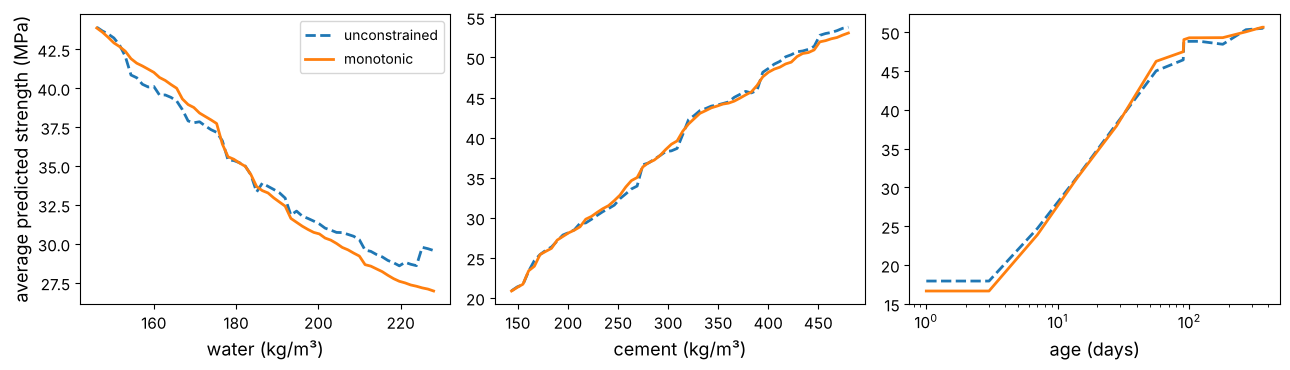

In [22]:
from sklearn.inspection import partial_dependence

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, (fi, label) in zip(axes, ((3, "water (kg/m³)"), (0, "cement (kg/m³)"), (7, "age (days)"))):
    for model, name, st in ((free_model, "unconstrained", "--"), (mono_model, "monotonic", "-")):
        pdp = partial_dependence(model, X_train, [fi], grid_resolution=60)
        grid = pdp["grid_values"][0]
        ax.plot(grid, pdp["average"][0], st, lw=2, label=name)
    ax.set_xlabel(label)
    if fi == 7:
        ax.set_xscale("log")
axes[0].set_ylabel("average predicted strength (MPa)")
axes[0].legend()
save_fig("partial_dependence_plot")
plt.show()

In [23]:
from sklearn.inspection import permutation_importance

imp = permutation_importance(mono_model, X_test, y_test, n_repeats=20, random_state=42,
                             scoring="neg_root_mean_squared_error")
pd.Series(imp.importances_mean, index=COLUMNS[:8], name="RMSE increase when shuffled (MPa)").sort_values(ascending=False).round(2)

cement              12.33
age                  9.32
slag                 4.69
water                3.57
fly_ash              1.72
coarse_agg           0.54
fine_agg             0.36
superplasticizer     0.12
Name: RMSE increase when shuffled (MPa), dtype: float64

## Quantify the Uncertainty

In [24]:
final_model = mono_model
oof_final = cross_val_predict(final_model, X_train, y_train, cv=cv, groups=groups)
residuals = y_train - oof_final
n = len(residuals)
q95 = np.quantile(residuals, np.ceil(0.95 * (n + 1)) / n)     # split-conformal, one-sided
print(f"95% one-sided conformal margin: {q95:.2f} MPa")
print(f"(residual std {residuals.std():.2f} MPa)")

95% one-sided conformal margin: 9.37 MPa
(residual std 5.73 MPa)


In [25]:
pred_test = final_model.predict(X_test)
lower = pred_test - q95
print(f"Test RMSE: {rmse(y_test, pred_test):.2f} MPa,  R² = {1 - np.mean((y_test - pred_test) ** 2) / y_test.var():.3f}")
print(f"Tests above their 95% lower bound: {np.mean(y_test >= lower):.1%}")
print(f"Physics baseline (Abrams), test RMSE: {rmse(y_test, AbramsModel().fit(X_train, y_train).predict(X_test)):.2f} MPa")
print(f"GP, test RMSE: {rmse(y_test, gp_model.predict(X_test)):.2f} MPa")

Test RMSE: 5.18 MPa,  R² = 0.897
Tests above their 95% lower bound: 95.4%
Physics baseline (Abrams), test RMSE: 7.14 MPa
GP, test RMSE: 5.45 MPa


Saving figure test_parity_plot


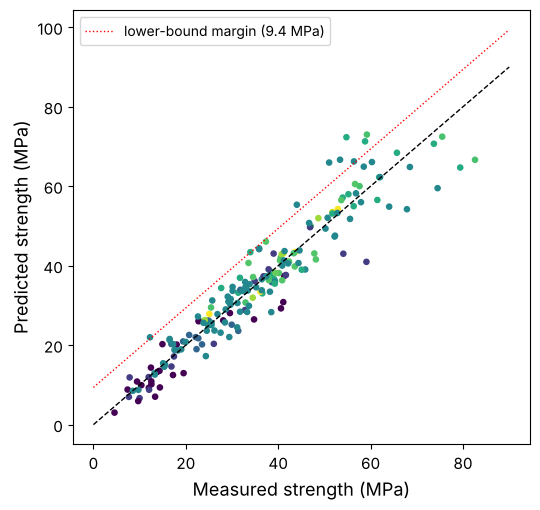

In [26]:
fig, ax = plt.subplots(figsize=(5.5, 5.2))
ax.scatter(y_test, pred_test, s=14, c=np.log(test_set.age), cmap="viridis")
ax.plot([0, 90], [0, 90], "k--", lw=1)
ax.plot([0, 90], [q95, 90 + q95], ":", color="red", lw=1, label=f"lower-bound margin ({q95:.1f} MPa)")
ax.set_xlabel("Measured strength (MPa)"); ax.set_ylabel("Predicted strength (MPa)")
ax.legend(loc="upper left")
save_fig("test_parity_plot")
plt.show()

## Use the Surrogate: Design a Low-Carbon Mix

Saving figure co2_vs_strength_plot


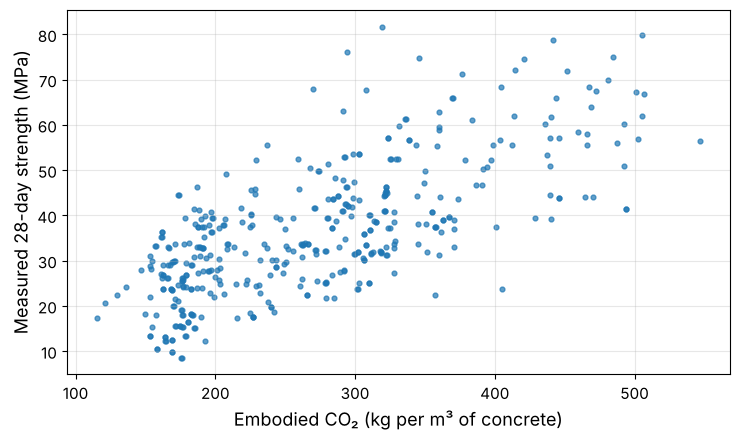

CO2 of the 28-day mixes: 115 to 547 kg/m³


In [27]:
# Approximate cradle-to-gate emission factors (kg CO2 per kg of material), typical of published
# inventories such as the ICE database; slag and fly ash are by-products with small allocations.
CO2_FACTOR = pd.Series({"cement": 0.91, "slag": 0.08, "fly_ash": 0.01, "water": 0.0003,
                        "superplasticizer": 1.9, "coarse_agg": 0.005, "fine_agg": 0.006})

def co2(mixes):
    return np.asarray(mixes, dtype=float)[:, :7] @ CO2_FACTOR.values

concrete["co2"] = co2(concrete[INGREDIENTS].values)
d28_all = concrete[concrete.age == 28]
plt.figure(figsize=(7.5, 4.5))
plt.scatter(d28_all.co2, d28_all.strength, s=12, alpha=0.7)
plt.xlabel("Embodied CO₂ (kg per m³ of concrete)"); plt.ylabel("Measured 28-day strength (MPa)")
plt.grid(True, alpha=0.3)
save_fig("co2_vs_strength_plot")
plt.show()
print(f"CO2 of the 28-day mixes: {d28_all.co2.min():.0f} to {d28_all.co2.max():.0f} kg/m³")

In [28]:
from sklearn.neighbors import NearestNeighbors

class ApplicabilityDomain:
    """A mix is 'inside the domain' if its nearest training mix (in standardized ingredient space)
    is no farther than the distances between training mixes themselves (95th percentile)."""
    def __init__(self, X, quantile=0.95):
        mixes = np.unique(np.asarray(X)[:, :7], axis=0)
        self.scaler = StandardScaler().fit(mixes)
        Z = self.scaler.transform(mixes)
        self.nn = NearestNeighbors(n_neighbors=2).fit(Z)
        self.threshold = np.quantile(self.nn.kneighbors(Z)[0][:, 1], quantile)
    def distance(self, X):
        return self.nn.kneighbors(self.scaler.transform(np.asarray(X)[:, :7]), n_neighbors=1)[0][:, 0]
    def contains(self, X):
        return self.distance(X) <= self.threshold

domain = ApplicabilityDomain(X_train)
print(f"Domain threshold: {domain.threshold:.2f} (standardized units)")
print(f"Test mixes inside the domain: {domain.contains(X_test).mean():.0%}")

Domain threshold: 1.53 (standardized units)
Test mixes inside the domain: 94%


In [29]:
from scipy.stats import qmc

LOW = concrete[INGREDIENTS].min().values
HIGH = concrete[INGREDIENTS].max().values
TARGET_VOLUME = 0.977          # m³ of solids + water per m³ of concrete (the rest is air)

def virtual_mixes(n, seed=42):
    """Random mixes that fill exactly 1 m³: sample six ingredients, solve for the coarse aggregate."""
    U = qmc.Sobol(d=6, scramble=True, seed=seed).random(n)
    idx = [0, 1, 2, 3, 4, 6]                         # all but coarse aggregate
    M = np.zeros((n, 8))
    M[:, idx] = LOW[idx] + U * (HIGH[idx] - LOW[idx])
    others = (M[:, idx] / DENSITY.values[idx]).sum(axis=1)
    M[:, 5] = (TARGET_VOLUME - others) * DENSITY["coarse_agg"]
    M[:, 7] = 28                                     # we design for 28-day strength
    ok = (M[:, 5] >= LOW[5]) & (M[:, 5] <= HIGH[5])
    return M[ok]

t0 = time.time()
V = virtual_mixes(2 ** 20)
V = V[domain.contains(V)]
V_pred = final_model.predict(V)
V_lower = V_pred - q95
V_co2 = co2(V)
print(f"{len(V):,} virtual mixes inside the domain, screened in {time.time() - t0:.0f} s")

87,934 virtual mixes inside the domain, screened in 3 s


In [30]:
def best_design(f_ck, pool=V, lower=V_lower, co2_=V_co2):
    ok = lower >= f_ck
    i = np.flatnonzero(ok)[np.argmin(co2_[ok])]
    return pool[i], lower[i], co2_[i]

def best_existing(f_ck, margin=8.0):
    """The lowest-carbon mix of the database whose measured 28-day strength reaches f_ck + 8 MPa,
    the usual margin between mean and characteristic strength."""
    ok = d28_all[d28_all.strength >= f_ck + margin]
    return ok.loc[ok.co2.idxmin()]

rows = []
for f_ck in (25, 30, 40, 50):
    mix, low, c = best_design(f_ck)
    ex = best_existing(f_ck)
    rows.append(dict(f_ck=f_ck, surrogate_co2=c, existing_co2=ex.co2, saving_pct=100 * (1 - c / ex.co2),
                     cement=mix[0], slag=mix[1], fly_ash=mix[2], water=mix[3], sp=mix[4],
                     w_b=mix[3] / mix[:3].sum(), predicted_mean=low + q95))
designs = pd.DataFrame(rows).set_index("f_ck")
designs.round(1)

,surrogate_co2,existing_co2,saving_pct,cement,slag,fly_ash,water,sp,w_b,predicted_mean
f_ck,,,,,,,,,,
25,124.4,156.6,20.5,104.7,200.4,153.9,164.7,1.1,0.4,37.1
30,129.1,173.6,25.6,108.2,138.0,172.8,130.5,4.1,0.3,42.1
40,144.9,207.7,30.3,106.3,259.4,36.3,158.5,9.1,0.4,52.6
50,230.6,270.0,14.6,223.5,133.8,77.1,157.0,3.2,0.4,59.5


Saving figure co2_pareto_plot


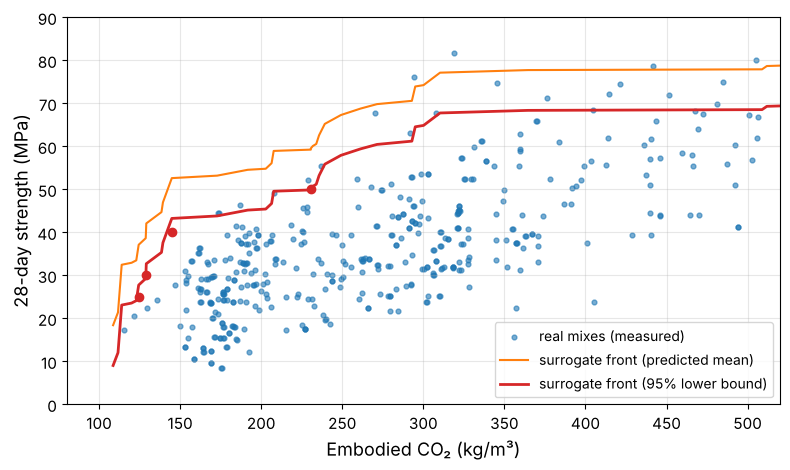

In [31]:
order = np.argsort(V_co2)
front = order[np.r_[True, np.diff(np.maximum.accumulate(V_lower[order])) > 0]]
plt.figure(figsize=(8, 4.8))
plt.scatter(d28_all.co2, d28_all.strength, s=12, alpha=0.6, label="real mixes (measured)")
plt.plot(V_co2[front], V_lower[front] + q95, "C1-", lw=1.5, label="surrogate front (predicted mean)")
plt.plot(V_co2[front], V_lower[front], "C3-", lw=2, label="surrogate front (95% lower bound)")
for f_ck in designs.index:
    plt.plot(designs.loc[f_ck, "surrogate_co2"], f_ck, "C3o")
plt.xlabel("Embodied CO₂ (kg/m³)"); plt.ylabel("28-day strength (MPa)")
plt.xlim(80, 520); plt.ylim(0, 90)
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)
save_fig("co2_pareto_plot")
plt.show()

In [32]:
# What if we had used the unconstrained model? Its wiggles can be exploited by the optimizer.
free_oof = cross_val_predict(free_model, X_train, y_train, cv=cv, groups=groups)
q95_free = np.quantile(y_train - free_oof, np.ceil(0.95 * (n + 1)) / n)
V_lower_free = free_model.predict(V) - q95_free
for name, lo_ in (("monotonic", V_lower), ("unconstrained", V_lower_free)):
    mix, low, c = best_design(40, lower=lo_)
    print(f"{name:13s} model: C40 mix at {c:.0f} kg CO2/m³, water {mix[3]:.0f}, cement {mix[0]:.0f}, "
          f"slag {mix[1]:.0f}, fly ash {mix[2]:.0f}, superplasticizer {mix[4]:.1f}")

monotonic     model: C40 mix at 145 kg CO2/m³, water 159, cement 106, slag 259, fly ash 36, superplasticizer 9.1
unconstrained model: C40 mix at 139 kg CO2/m³, water 163, cement 112, slag 295, fly ash 151, superplasticizer 1.8


In [33]:
# Sanity check of the screened C40 design: its nearest real mixes, and a second opinion from the GP
def nearest_real(mix, k=4):
    d = np.linalg.norm(domain.scaler.transform(d28_all[INGREDIENTS].values) - domain.scaler.transform(mix[None, :7]), axis=1)
    return d28_all.assign(distance=d).nsmallest(k, "distance")[INGREDIENTS + ["strength", "distance"]]

mix_g, low_g, c_g = best_design(40)
gp_mu, gp_sd = gp_model.predict(mix_g[None], return_std=True)
print(f"Screened C40 design: boosting predicts {low_g + q95:.1f} MPa, the GP {gp_mu[0]:.1f} ± {gp_sd[0]:.1f} MPa")
nearest_real(mix_g).round(1)

Screened C40 design: boosting predicts 52.6 MPa, the GP 47.5 ± 10.7 MPa


,cement,slag,fly_ash,water,superplasticizer,coarse_agg,fine_agg,strength,distance
938,150.0,236.8,0.0,173.8,11.9,1069.3,674.8,37.4,1.5
875,150.0,237.0,0.0,174.0,12.0,1069.0,675.0,37.4,1.5
841,160.0,250.0,0.0,168.0,12.0,1049.0,688.0,39.5,1.5
998,159.8,250.0,0.0,168.4,12.2,1049.3,688.2,39.5,1.6


In [34]:
# A safer search: perturb real recipes by about ±10% (a "trust region" around the data),
# keep the mixes close to real ones, and require BOTH models to agree on the lower bound.
def local_mixes(n_per_mix=300, scale=0.1, seed=42):
    rng = np.random.default_rng(seed)
    base = np.repeat(np.unique(X_train[:, :7], axis=0), n_per_mix, axis=0)
    M = base * np.exp(rng.normal(0, scale, base.shape))
    M *= (TARGET_VOLUME / (M / DENSITY.values).sum(axis=1))[:, None]     # fill exactly 1 m³
    ok = np.all((M >= LOW) & (M <= HIGH), axis=1)
    return np.c_[M[ok], np.full(ok.sum(), 28.0)]

near_domain = ApplicabilityDomain(X_train, quantile=0.75)
T = local_mixes()
T = T[near_domain.contains(T)]
gp_mu, gp_sd = gp_model.predict(T, return_std=True)
T_lower = np.minimum(final_model.predict(T) - q95, gp_mu - 1.645 * gp_sd)   # the more cautious of the two
T_co2 = co2(T)
print(f"GP lower bound (mean - 1.645 sd) coverage on the test set: "
      f"{np.mean(y_test >= gp_model.predict(X_test) - 1.645 * gp_model.predict(X_test, return_std=True)[1]):.1%}")
# For a fair comparison, certify the real mixes with the same rule (both models' lower bounds)
X28 = d28_all[COLUMNS[:8]].values.astype(float)
gm28, gs28 = gp_model.predict(X28, return_std=True)
real_lower = np.minimum(final_model.predict(X28) - q95, gm28 - 1.645 * gs28)

def best_certified_real(f_ck):
    ok = d28_all[real_lower >= f_ck]
    return ok.loc[ok.co2.idxmin()]

rows = []
for f_ck in (25, 30, 40, 50):
    mix, low, c = best_design(f_ck, pool=T, lower=T_lower, co2_=T_co2)
    cert = best_certified_real(f_ck)
    rows.append(dict(f_ck=f_ck, safe_co2=c, best_certified_real_co2=cert.co2, saving_pct=100 * (1 - c / cert.co2),
                     best_measured_real_co2=best_existing(f_ck).co2, cement=mix[0], slag=mix[1], fly_ash=mix[2],
                     water=mix[3], sp=mix[4], w_b=mix[3] / mix[:3].sum()))
safe_designs = pd.DataFrame(rows).set_index("f_ck")
print(f"{len(T):,} candidates near real mixes")
safe_designs.round(1)

GP lower bound (mean - 1.645 sd) coverage on the test set: 95.4%
25,729 candidates near real mixes


,safe_co2,best_certified_real_co2,saving_pct,best_measured_real_co2,cement,slag,fly_ash,water,sp,w_b
f_ck,,,,,,,,,,
25,139.4,160.9,13.4,156.6,113.1,210.8,159.7,177.7,4.7,0.4
30,155.1,173.6,10.7,173.6,121.2,170.8,125.4,165.4,10.7,0.4
40,214.3,237.0,9.6,207.7,173.9,291.1,0.0,162.8,12.3,0.4
50,267.7,291.6,8.2,270.0,242.8,202.7,133.1,153.6,10.7,0.3


In [35]:
mix_s, low_s, c_s = best_design(40, pool=T, lower=T_lower, co2_=T_co2)
print(f"Safe C40 design: boosting {final_model.predict(mix_s[None])[0]:.1f} MPa, "
      f"GP {gp_model.predict(mix_s[None])[0]:.1f} MPa, agreed lower bound {low_s:.1f} MPa")
nearest_real(mix_s).round(1)

Safe C40 design: boosting 49.8 MPa, GP 51.0 MPa, agreed lower bound 40.4 MPa


,cement,slag,fly_ash,water,superplasticizer,coarse_agg,fine_agg,strength,distance
841,160.0,250.0,0.0,168.0,12.0,1049.0,688.0,39.5,0.6
998,159.8,250.0,0.0,168.4,12.2,1049.3,688.2,39.5,0.7
938,150.0,236.8,0.0,173.8,11.9,1069.3,674.8,37.4,1.1
875,150.0,237.0,0.0,174.0,12.0,1069.0,675.0,37.4,1.1


## A Retrospective Lab Campaign: Bayesian Optimization on Real Tests

In [36]:
from scipy.stats import norm

pool = d28_all.drop_duplicates(INGREDIENTS).reset_index(drop=True)
pool_X = pool[COLUMNS[:8]].values
pool_y = pool.strength.values
pool_co2 = pool.co2.values
TARGET = 48.0                                         # mean strength needed for a C40 concrete
best_possible = pool_co2[pool_y >= TARGET].min()

def campaign_gp():
    return make_pipeline(MixFeatures(), StandardScaler(), GaussianProcessRegressor(
        C(1.0) * Matern(np.ones(13), (1e-2, 1e3), nu=2.5) + WhiteKernel(0.1, (1e-3, 1.0)),
        normalize_y=True, random_state=0))

def run_campaign(seed, n_init=10, n_total=60, strategy="bo"):
    rng = np.random.default_rng(seed)
    tested = list(rng.choice(len(pool), n_init, replace=False))
    while len(tested) < n_total:
        rest = np.setdiff1d(np.arange(len(pool)), tested)
        if strategy == "random":
            tested.append(rng.choice(rest))
            continue
        gp_ = campaign_gp().fit(pool_X[tested], pool_y[tested])
        mu, sd = gp_.predict(pool_X[rest], return_std=True)
        feas = pool_y[tested] >= TARGET
        best = pool_co2[tested][feas].min() if feas.any() else pool_co2.max()
        acq = np.maximum(best - pool_co2[rest], 0) * norm.cdf((mu - TARGET) / sd)
        tested.append(rest[np.argmax(acq)])
    tested = np.array(tested)
    found = np.where(pool_y[tested] >= TARGET, pool_co2[tested], np.inf)
    return np.minimum.accumulate(found)

t0 = time.time()
traces = {s: np.array([run_campaign(seed, strategy=s) for seed in range(10)]) for s in ("random", "bo")}
print(f"{len(pool)} distinct mixes tested at 28 days; best possible C40 mix: {best_possible:.1f} kg CO2/m³"
      f" ({time.time() - t0:.0f} s)")
for s, tr_ in traces.items():
    med = np.median(tr_, axis=0)
    print(f"{s:6s}: median best after 20 tests {med[19]:.1f}, after 40 tests {med[39]:.1f}, "
          f"after 60 tests {med[59]:.1f} kg CO2/m³")

417 distinct mixes tested at 28 days; best possible C40 mix: 207.7 kg CO2/m³ (43 s)
random: median best after 20 tests 319.0, after 40 tests 274.1, after 60 tests 274.1 kg CO2/m³
bo    : median best after 20 tests 252.4, after 40 tests 229.1, after 60 tests 229.1 kg CO2/m³


Saving figure lab_campaign_plot


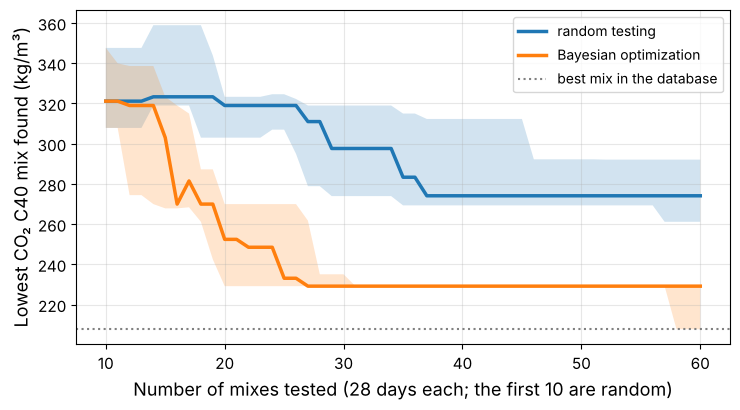

In [37]:
plt.figure(figsize=(7.5, 4.2))
for s, label in (("random", "random testing"), ("bo", "Bayesian optimization")):
    tr_ = np.where(np.isfinite(traces[s]), traces[s], np.nan)
    k = np.arange(10, 61)                            # after the 10 random initial tests
    plt.plot(k, np.nanmedian(tr_, axis=0)[9:], lw=2.5, label=label)
    plt.fill_between(k, np.nanpercentile(tr_, 25, axis=0)[9:], np.nanpercentile(tr_, 75, axis=0)[9:], alpha=0.2)
plt.axhline(best_possible, color="gray", ls=":", label="best mix in the database")
plt.xlabel("Number of mixes tested (28 days each; the first 10 are random)"); plt.ylabel("Lowest CO₂ C40 mix found (kg/m³)")
plt.legend()
plt.grid(True, alpha=0.3)
save_fig("lab_campaign_plot")
plt.show()

## Present Your Solution

In [38]:
mix40, low40, c40 = mix_s, low_s, c_s
ex40 = best_certified_real(40)
sol = pd.DataFrame({"proposed C40 mix": list(mix40[:7]) + [c40, final_model.predict(mix40[None])[0], low40],
                    "best certified real C40 mix": list(ex40[INGREDIENTS]) + [ex40.co2, ex40.strength, real_lower[d28_all.index.get_loc(ex40.name)]]},
                   index=INGREDIENTS + ["CO2 (kg/m³)", "28-day strength (MPa, predicted / measured)", "agreed 95% lower bound (MPa)"])
sol.round(1)

,proposed C40 mix,best certified real C40 mix
cement,173.9,218.2
slag,291.1,54.6
fly_ash,0.0,123.8
water,162.8,140.8
superplasticizer,12.3,11.9
coarse_agg,1031.6,1075.7
fine_agg,705.8,792.7
CO2 (kg/m³),214.3,237.0
"28-day strength (MPa, predicted / measured)",49.8,55.5
agreed 95% lower bound (MPa),40.4,42.5


## Launch, Monitor, and Maintain

In [39]:
import joblib
joblib.dump(dict(model=final_model, q95=q95, domain=domain), "concrete_surrogate.pkl")
surrogate = joblib.load("concrete_surrogate.pkl")
surrogate["model"].predict(mix40[None])                     # warm-up call
t0 = time.time()
p = surrogate["model"].predict(mix40[None])
print(f"Prediction for the proposed mix: {p[0]:.1f} MPa (boosting lower bound {p[0] - surrogate['q95']:.1f})"
      f" in {1e3 * (time.time() - t0):.1f} ms; inside the domain: {surrogate['domain'].contains(mix40[None])[0]}")

Prediction for the proposed mix: 49.8 MPa (boosting lower bound 40.4) in 10.8 ms; inside the domain: True


In [40]:
import json
os.makedirs("animations", exist_ok=True)
hgb = final_model[-1]
trees = []
for (tree,) in hgb._predictors:
    nd = tree.nodes
    trees.append([nd["feature_idx"].tolist(), nd["num_threshold"].tolist(), nd["left"].tolist(),
                  nd["right"].tolist(), nd["is_leaf"].astype(int).tolist(), nd["value"].tolist()])
b28 = d28_all.cement + d28_all.slag + d28_all.fly_ash
med = {s: np.nanmedian(np.where(np.isfinite(t), t, np.nan), axis=0) for s, t in traces.items()}
anim = dict(
    trees=trees, baseline=float(np.ravel(hgb._baseline_prediction)[0]), q95=float(q95),
    low=LOW.tolist(), high=HIGH.tolist(), density=DENSITY.values.tolist(), co2_factor=CO2_FACTOR.values.tolist(),
    target_volume=TARGET_VOLUME,
    real=[[round(float(c), 1), round(float(s), 2), round(float(w), 3), round(float(f), 3)] for c, s, w, f in
          zip(d28_all.co2, d28_all.strength, d28_all.water / b28, (d28_all.slag + d28_all.fly_ash) / b28)],
    front=[[round(float(V_co2[i]), 1), round(float(V_lower[i]), 2)] for i in front[::max(1, len(front) // 300)]],
    designs={int(k): [round(float(v), 1) for v in best_design(k, pool=T, lower=T_lower, co2_=T_co2)[0][:7]] for k in designs.index},
    abrams=abrams.params_.tolist(),
    campaign={s: [None if not np.isfinite(v) else round(float(v), 1) for v in m] for s, m in med.items()},
    best_possible=float(best_possible), check=dict(x=mix40.tolist(), y=float(final_model.predict(mix40[None])[0])))
with open(os.path.join("animations", "data.json"), "w") as f:
    json.dump(anim, f, separators=(",", ":"))
print("exported", len(trees), "trees,", os.path.getsize(os.path.join("animations", "data.json")) // 1024, "KB")

exported 800 trees, 856 KB
